In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
 

In [18]:
# ---------------------------------------------------
# 1. LOAD DATA
# ---------------------------------------------------
df = pd.read_csv("1-uber.csv")
print(df.head())
print(df.info())
 

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [19]:
 # ---------------------------------------------------
# 2. PREPROCESSING
# ---------------------------------------------------
# Remove missing values
print(df.isnull().sum())
df = df.dropna()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [20]:

# Remove columns that are not useful
df = df.drop(columns=["Unnamed: 0", "key"])
 
# Take only the hour from pickup_datetime
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])
df["hour"] = df["pickup_datetime"].dt.hour
df = df.drop(columns=["pickup_datetime"])

In [21]:
# Calculate distance between pickup and dropoff (Euclidean formula)
df["distance"] = np.sqrt(
    (df["dropoff_latitude"] - df["pickup_latitude"]) ** 2 +
    (df["dropoff_longitude"] - df["pickup_longitude"]) ** 2
)
 


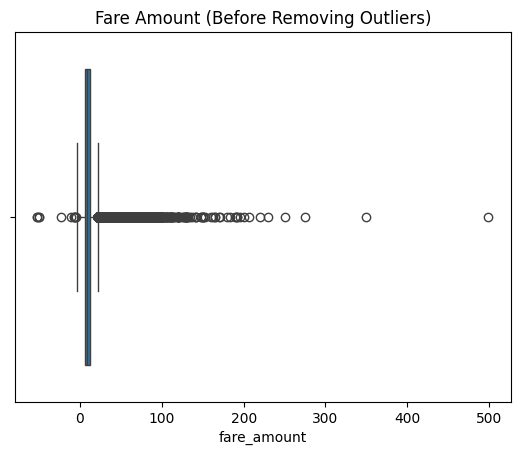

In [22]:
# ---------------------------------------------------
# 3. IDENTIFY AND REMOVE OUTLIERS
# ---------------------------------------------------
# Boxplot before removing outliers
sns.boxplot(x=df["fare_amount"])
plt.title("Fare Amount (Before Removing Outliers)")
plt.show()
 

In [23]:

# Remove wrong values
df = df[df["fare_amount"] > 0]
df = df[df["passenger_count"].between(1, 6)]
df = df[df["pickup_latitude"].between(-90, 90) & df["dropoff_latitude"].between(-90, 90)]
df = df[df["pickup_longitude"].between(-180, 180) & df["dropoff_longitude"].between(-180, 180)]
df = df[df["distance"] > 0]

In [24]:

# IQR method on fare_amount
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
 
print("Number of outliers:", ((df["fare_amount"] < lower) | (df["fare_amount"] > upper)).sum())
df = df[(df["fare_amount"] >= lower) & (df["fare_amount"] <= upper)]


Number of outliers: 16619


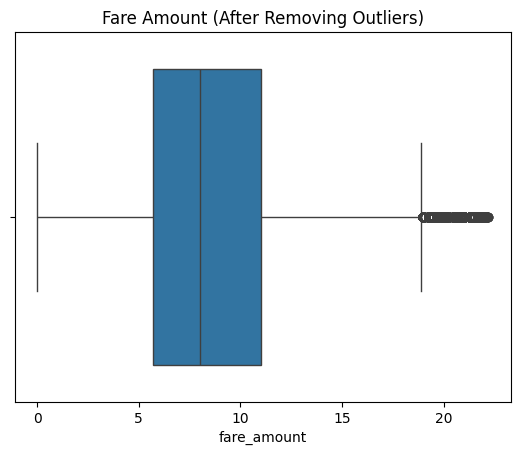

In [25]:

# Boxplot after removing outliers
sns.boxplot(x=df["fare_amount"])
plt.title("Fare Amount (After Removing Outliers)")
plt.show()

In [26]:
# ---------------------------------------------------
# 4. CORRELATION
# ---------------------------------------------------
corr = df.corr()
print(corr)

                   fare_amount  pickup_longitude  pickup_latitude  \
fare_amount           1.000000          0.002106        -0.002682   
pickup_longitude      0.002106          1.000000        -0.929906   
pickup_latitude      -0.002682         -0.929906         1.000000   
dropoff_longitude    -0.001294          0.573715        -0.678720   
dropoff_latitude     -0.000148         -0.672589         0.815229   
passenger_count       0.012966          0.006591        -0.007944   
hour                 -0.013137          0.002130        -0.002013   
distance              0.002231          0.497620        -0.310114   

                   dropoff_longitude  dropoff_latitude  passenger_count  \
fare_amount                -0.001294         -0.000148         0.012966   
pickup_longitude            0.573715         -0.672589         0.006591   
pickup_latitude            -0.678720          0.815229        -0.007944   
dropoff_longitude           1.000000         -0.936705         0.009205   
dro

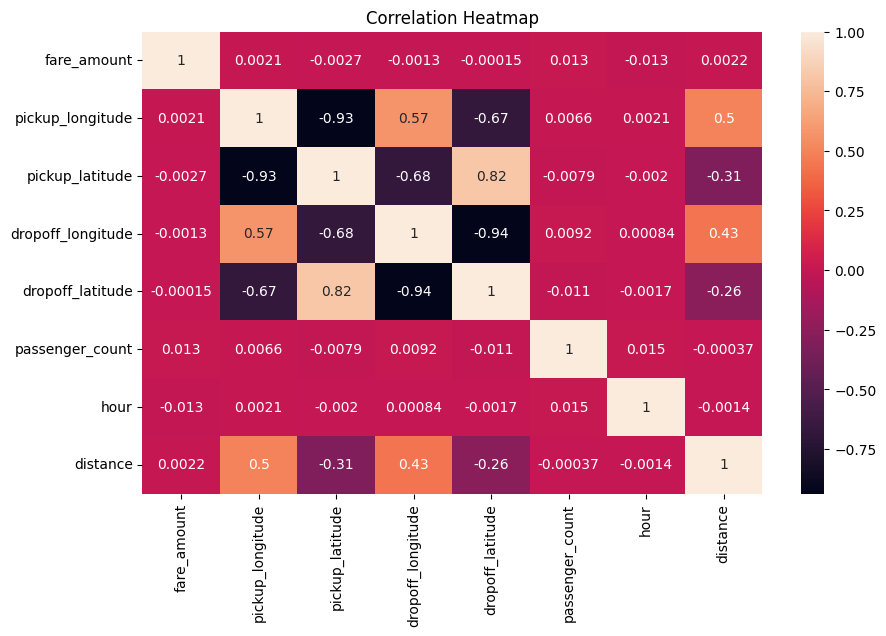

In [31]:

plt.figure(figsize=(10, 6))
# sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
sns.heatmap(corr, annot=True)
plt.title("Correlation Heatmap")
plt.show()
 

In [28]:

 
# ---------------------------------------------------
# 5. TRAIN-TEST SPLIT
# ---------------------------------------------------
X = df.drop("fare_amount", axis=1)
y = df["fare_amount"]
 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
 

In [29]:
 
# ---------------------------------------------------
# 6. LINEAR REGRESSION
# ---------------------------------------------------
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)
 
r2_lr = r2_score(y_test, pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, pred_lr))
 


In [32]:
# ---------------------------------------------------
# 7. RANDOM FOREST REGRESSION
# ---------------------------------------------------
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
 
r2_rf = r2_score(y_test, pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, pred_rf))
 


In [33]:

# ---------------------------------------------------
# 8. COMPARE MODELS
# ---------------------------------------------------
result = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "R2 Score": [r2_lr, r2_rf],
    "RMSE": [rmse_lr, rmse_rf]
})
print(result)


               Model  R2 Score      RMSE
0  Linear Regression  0.000212  4.143063
1      Random Forest  0.735436  2.131243


In [34]:

if r2_rf > r2_lr and rmse_rf < rmse_lr:
    print("Random Forest performs better (higher R2, lower RMSE).")
else:
    print("Linear Regression performs better.")


Random Forest performs better (higher R2, lower RMSE).
